# Notebook for MIRI coronagraphic data

This notebook starts from the stage 1 of the jwst pipeline reduction (you can skip this step) to the final image of the sceince target subtracted from the reference star.
- Stage 1
- Stage 2 (we skiped the background subtraction and the flat field correction, see Boccaletti et al. 2024)
- Build of the master background subtraction
- Subtraction of the reference (best dither, or linear combination of the 9 dithers)

# 1. Configuration

In [1]:
#Basic import necessary for configuration
import os

The directory paths for processing data need to be modified

In [2]:
#-----------------------Data mode directories------------------------
# Directory paths for processing data
PID = '3662'
TARGET = 'TWA7'
basedir = f'/Users/mcourtoux/these/raw_data/P{PID}/{TARGET}/'

# Directory paths pointing to where science observation data are
coron_r1_dir = os.path.join(basedir, 'obs001/') # roll 1
coron_r2_dir = os.path.join(basedir, 'obs002/') # roll 2

# Directory paths pointing to where reference target observation data are
# it is supposed to be 5 or 9 files
ref_targ_dir = os.path.join(basedir, 'obs004/')

# Directory pointing to where background observation data are
# Usually 2 files of background
bg_sci_dir = os.path.join(basedir, 'obs003/')
bg_ref_targ_dir = os.path.join(basedir, 'obs005/')

#------------------------Set Processing Steps-------------------------"
use_mask = '4QPM_1140'
use_filter = 'F1140C'

# Science processing
dodet1 = False   # calwebb_detector1
doimage2 = True  # calwebb_image2
docoron3 = True     # calwebb_coron3

#Background processing
dodet1bg = False    # calwebb_detector1
doimage2bg = True  # calwebb_image2

## Set CRDS context and server

In [3]:
os.environ['CRDS_PATH'] = '/Users/mcourtoux/these/astro_data/crds_cache'

In [4]:
# Check whether the CRDS server URL has been set.  If not, set it.
if (os.getenv('CRDS_SERVER_URL') is None):
    os.environ['CRDS_SERVER_URL'] = 'https://jwst-crds.stsci.edu'

In [5]:
# Echo CRDS path in use
print('CRDS local filepath:', os.environ['CRDS_PATH'])
print('CRDS file server:', os.environ['CRDS_SERVER_URL'])

CRDS local filepath: /Users/mcourtoux/these/astro_data/crds_cache
CRDS file server: https://jwst-crds.stsci.edu


# 2. Package imports

In [6]:
#-------------------------General Imports----------------------------
import glob
import time
from pathlib import Path
import re

import numpy as np
import scipy.optimize as optimize
from scipy.ndimage import rotate, median_filter, shift

#-----------------------Astropy Imports----------------------------
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
from astropy.stats import sigma_clip

#----------------------Plotting Imports----------------------------
import matplotlib.pyplot as plt

In [7]:
#----------------JWST Calibration Pipeline Imports ----------------
import jwst
import crds
import logging

# JWST pipelines (each encompassing many steps)
#from jwst.pipeline import Detector1Pipeline
from jwst.pipeline import Image2Pipeline
from jwst.pipeline import Coron3Pipeline

# JWST pipelines utilities
from jwst import datamodels  # JWST datamodels
from jwst.associations import asn_from_list as afl # Tools for creating association files
from jwst.associations.lib.rules_level2_base import DMSLevel2bBase  # Definition of a Lvl2 association file
from jwst.associations.lib.rules_level3_base import DMS_Level3_Base  # Definition of a Lvl3 association file

from jwst.stpipe import Step   # The wrapper class for pipeline steps

#Functions utils for the reduction (stage 2 and stage 3)
from jwst_reduction.subtract_background import subtract_background
from jwst_reduction.mask import create_annular_mask
from jwst_reduction.sigma_clipping import clean_data
from jwst_reduction.reference_subtraction import opt_1ref, optimize_refs, reference_subtract 
from jwst_reduction.utils import crop_center, rotate_images
from jwst_reduction.load_ref_library import load_reference_library

# Echo pipeline version and CRDS context in use
#print("JWST Calibration Pipeline Version = {}".format(jwst.__version__))
#print("Using CRDS Context = {}".format(crds.get_context_name('jwst')))

## 3. Directory setup

In [8]:
# Define output subdirectories to keep science data products organized
# sci roll 1
det1_sci_r1_dir = os.path.join(coron_r1_dir, 'stage1')  # calwebb_detector1 pipeline outputs will go here
image2_sci_r1_dir = os.path.join(coron_r1_dir, 'stage2')  # calwebb_image2 pipeline outputs will go here
#image2_sci_bkg_sub_r1_dir = os.path.join(coron_r1_dir, 'stage2_bkg_subtract')  # calwebb_image2 pipeline with bkg subtraction outputs will go here

# sci roll 2
det1_sci_r2_dir = os.path.join(coron_r2_dir, 'stage1')  # calwebb_detector1 pipeline outputs will go here
image2_sci_r2_dir = os.path.join(coron_r2_dir, 'stage2')  # calwebb_image2 pipeline outputs will go here
#image2_sci_bkg_sub_r2_dir = os.path.join(coron_r2_dir, 'stage2_bkg_subtract') # calwebb_image2 pipeline with bkg subtraction outputs will go here

# Define output subdirectories to keep PSF reference target data products organized
det1_ref_targ_dir = os.path.join(ref_targ_dir, 'stage1')  # calwebb_detector1 pipeline outputs will go here
image2_ref_targ_dir = os.path.join(ref_targ_dir, 'stage2')  # calwebb_image2 pipeline outputs will go here
#image2_ref_targ_bkg_sub_dir = os.path.join(ref_targ_dir, 'stage2_bkg_subtract')  # calwebb_image2 pipeline with bkg subtraction outputs will go here

# Define output subdirectories to keep background data products organized
# Sci Bkg
det1_bg_sci_dir = os.path.join(bg_sci_dir, 'stage1')  # calwebb_detector1 pipeline outputs will go here
image2_bg_sci_dir = os.path.join(bg_sci_dir, 'stage2')  # calwebb_image2 pipeline outputs will go here

# Ref target Bkg
det1_bg_ref_targ_dir = os.path.join(bg_ref_targ_dir, 'stage1')  # calwebb_detector1 pipeline outputs will go here
image2_bg_ref_targ_dir = os.path.join(bg_ref_targ_dir, 'stage2')  # calwebb_image2 pipeline outputs will go here

coron3_dir = os.path.join(basedir, 'stage3')

# We need to check that the desired output directories exist, and if not create them
det1_dirs = [det1_sci_r1_dir, det1_sci_r2_dir, det1_ref_targ_dir, det1_bg_sci_dir, det1_bg_ref_targ_dir]
image2_dirs = [image2_sci_r1_dir, image2_sci_r2_dir, image2_ref_targ_dir, image2_bg_sci_dir, image2_bg_ref_targ_dir]
#image2_bkg_sub_dirs = [image2_sci_bkg_sub_r1_dir, image2_sci_bkg_sub_r2_dir, image2_ref_targ_bkg_sub_dir]

for dirs in det1_dirs:
    if not os.path.exists(dirs):
        os.makedirs(dirs)
for dirs in image2_dirs:
    if not os.path.exists(dirs):
        os.makedirs(dirs)
#for dirs in image2_bkg_sub_dirs:
#    if not os.path.exists(dirs):
#        os.makedirs(dirs)
if not os.path.exists(coron3_dir):
    os.makedirs(coron3_dir)

# 4. Detector1 Pipeline

Skip this section if you already the rate files

Go to the next section 5. Image2Pipeline

In [9]:
# Set up a dictionnary to define how the Detector1 pipeline should be configured
det1dict = {}
det1dict['group_scale'], det1dict['dq_init'], det1dict['emicorr'], det1dict['saturation'] = {},{},{},{}
det1dict['firstframe'], det1dict['lastframe'], det1dict['reset'], det1dict['linearity'], det1dict['rscd'] = {},{},{},{},{}
det1dict['dark_current'], det1dict['refpix'], det1dict['jump'], det1dict['ramp_fit'], det1dict['gain_scale'] = {},{},{},{},{}

#skipping a step
#det1dict['refpix']['skip'] = True

# Turn on multi-core processing (off by default). Choose what fraction of cores to use (quarter, half, or all)
det1dict['jump']['maximum_cores'] = 'half'

## Calibrating Science Files

In [10]:
# Input files of the form *uncal.fits from the science observation
sstring1 = os.path.join(coron_r1_dir, 'jw*mirimage*uncal.fits')
sstring2 = os.path.join(coron_r2_dir, 'jw*mirimage*uncal.fits')

uncal_sci_r1_files = sorted(glob.glob(sstring1))
uncal_sci_r2_files = sorted(glob.glob(sstring2))

# Check that these are the correct mask/filter to use
print('Found ' + str((len(uncal_sci_r1_files) + len(uncal_sci_r2_files))) + ' science input files')

Found 0 science input files


In [11]:
# Run the pipeline on these input files by a simple loop over files using

if dodet1:
    for file in uncal_sci_r1_files:
        Detector1Pipeline.call(file, steps=det1dict, save_results=True, output_dir=det1_sci_r1_dir)
    for file in uncal_sci_r2_files:
        Detector1Pipeline.call(file, steps=det1dict, save_results=True, output_dir=det1_sci_r2_dir)
else:
    print('Skipping Detector1 processing dor SCI data')

logging.getLogger('stpipe').setLevel(logging.WARNING)

Skipping Detector1 processing dor SCI data


It seems that gain_scale was skipped because of the GAINFACT not found in the gain reference file *'/home/mcourtoux/volumes/dio/data5/crds_cache/references/jwst/miri/jwst_miri_gain_0045.fits'.*
But, according to the doc, this step is especially usefull for NIR instruments.

## Calibrating PSF Reference Target Files

In [12]:
sstring = os.path.join(ref_targ_dir, 'jw*mirimage*uncal.fits')
uncal_ref_targ_files = sorted(glob.glob(sstring))

print('Found ' + str(len(uncal_ref_targ_files)) + ' PSF reference input files.')

Found 0 PSF reference input files.


In [13]:
# Run the pipeline on these input files by a simple loop over files using
if dodet1:
    for file in uncal_ref_targ_files:
        print(file)
        Detector1Pipeline.call(file, steps=det1dict, save_results=True, output_dir=det1_ref_targ_dir)
else:
    print('Skipping Detector1 processing for PSF reference data')

logging.getLogger('stpipe').setLevel(logging.WARNING)

Skipping Detector1 processing for PSF reference data


## Calibrating Background Files

In [14]:
sstring1 = os.path.join(bg_sci_dir, 'jw*mirimage*uncal.fits')
sstring2 = os.path.join(bg_ref_targ_dir, 'jw*mirimage*uncal.fits')

uncal_bg_sci_files = sorted(glob.glob(sstring1))
uncal_bg_ref_targ_files = sorted(glob.glob(sstring2))

print('Found ' + str(len(uncal_bg_sci_files) + len(uncal_bg_ref_targ_files)) + ' background input files.')

Found 0 background input files.


In [15]:
# Run the pipeline on these input files by a simple loop over files using
if dodet1:
    for file in uncal_bg_sci_files:
        Detector1Pipeline.call(file, steps=det1dict, save_results=True, output_dir=det1_bg_sci_dir)
    for file in uncal_bg_ref_targ_files:
        Detector1Pipeline.call(file, steps=det1dict, save_results=True, output_dir=det1_bg_ref_targ_dir)
else:
    print('Skipping Detector1 processing for BG data')

logging.getLogger('stpipe').setLevel(logging.WARNING)

Skipping Detector1 processing for BG data


# 5. Image2Pipeline

We skip the flat field correction because it increases the glow stick effect (Boccaletti et al. 2024)

We prefer to build the master background instead of the average of backgrounds as in the pipeline.

In [16]:
# Set up a dictionnary to define how the Image2 pipeline should be configured
image2dict = {}
image2dict['assign_wcs'], image2dict['bkg_subtract'], image2dict['flat_field'], image2dict['photom'], image2dict['resample'] = {},{},{},{},{}

# skip bkg_subtract
image2dict['bkg_subtract']['skip'] = True # True because we prefer to use min bkg instead of the average of bkgs
image2dict['flat_field']['skip'] = True   # True because it increases the glowstick


In [17]:
# Identify Science Files
# Roll 1
sstring = os.path.join(coron_r1_dir, 'jw*mirimage*rate.fits')  # Use files from the detector1 output folder
sci_r1_files = sorted(glob.glob(sstring))

# Roll 2
sstring = os.path.join(coron_r2_dir, 'jw*mirimage*rate.fits')  # Use files from the detector1 output folder
sci_r2_files = sorted(glob.glob(sstring))

#Identify PSF Ref Target Files
sstring = os.path.join(ref_targ_dir, 'jw*mirimage*rate.fits')
ref_targ_files = sorted(glob.glob(sstring))

# Background files
# Sci bkg
sstring = os.path.join(bg_sci_dir, 'jw*mirimage*rate.fits')
bg_sci_files = sorted(glob.glob(sstring))

# Ref Target bkg
sstring = os.path.join(bg_ref_targ_dir, 'jw*mirimage*rate.fits')
bg_ref_targ_files = sorted(glob.glob(sstring))

print('Found ' + str(len(sci_r1_files) + len(sci_r2_files)) + ' science files')
print('Found ' + str(len(ref_targ_files)) + ' reference files')
print('Found ' + str(len(bg_sci_files)) + ' science background files')
print('Found ' + str(len(bg_ref_targ_files)) + ' reference background files')

Found 2 science files
Found 9 reference files
Found 2 science background files
Found 2 reference background files


In [18]:
if doimage2:
    for file in ref_targ_files:
        Image2Pipeline.call(file, steps=image2dict, save_bsub=False, save_results=True, output_dir=image2_ref_targ_dir)  
else:
    print('Skipping Image2 processing for PSF REF target data')

2026-11-19 11:32:12,541 - CRDS - INFO -  Calibration SW Found: jwst 3.0.0 (/Users/mcourtoux/anaconda3/envs/pipeline_jwst/lib/python3.13/site-packages/jwst-3.0.0.dist-info)
2026-11-19 11:32:12,880 - stpipe.step - INFO - PARS-RESAMPLESTEP parameters found: /Users/mcourtoux/these/astro_data/crds_cache/references/jwst/miri/jwst_miri_pars-resamplestep_0001.asdf
2026-11-19 11:32:12,887 - stpipe.step - INFO - Image2Pipeline instance created.
2026-11-19 11:32:12,887 - stpipe.step - INFO - BackgroundStep instance created.
2026-11-19 11:32:12,888 - stpipe.step - INFO - AssignWcsStep instance created.
2026-11-19 11:32:12,888 - stpipe.step - INFO - FlatFieldStep instance created.
2026-11-19 11:32:12,889 - stpipe.step - INFO - PhotomStep instance created.
2026-11-19 11:32:12,889 - stpipe.step - INFO - ResampleStep instance created.
2026-11-19 11:32:12,934 - stpipe.step - INFO - Step Image2Pipeline running with args ('/Users/mcourtoux/these/raw_data/P3662/TWA7/obs004/jw03662004001_04101_00001_mirima

In [19]:
if doimage2:
    for file in bg_sci_files:
        Image2Pipeline.call(file, steps=image2dict, save_bsub=False, save_results=True, output_dir=image2_bg_sci_dir)  
    for file in bg_ref_targ_files:
        Image2Pipeline.call(file, steps=image2dict, save_bsub=False, save_results=True, output_dir=image2_bg_ref_targ_dir)  
else:
    print('Skipping Image2 processing for BG data')

2026-11-19 11:32:16,405 - stpipe.step - INFO - PARS-RESAMPLESTEP parameters found: /Users/mcourtoux/these/astro_data/crds_cache/references/jwst/miri/jwst_miri_pars-resamplestep_0001.asdf
2026-11-19 11:32:16,411 - stpipe.step - INFO - Image2Pipeline instance created.
2026-11-19 11:32:16,412 - stpipe.step - INFO - BackgroundStep instance created.
2026-11-19 11:32:16,413 - stpipe.step - INFO - AssignWcsStep instance created.
2026-11-19 11:32:16,413 - stpipe.step - INFO - FlatFieldStep instance created.
2026-11-19 11:32:16,414 - stpipe.step - INFO - PhotomStep instance created.
2026-11-19 11:32:16,414 - stpipe.step - INFO - ResampleStep instance created.
2026-11-19 11:32:16,462 - stpipe.step - INFO - Step Image2Pipeline running with args ('/Users/mcourtoux/these/raw_data/P3662/TWA7/obs003/jw03662003001_02101_00001_mirimage_rate.fits',).
2026-11-19 11:32:16,465 - stpipe.step - INFO - Step Image2Pipeline parameters are:
  pre_hooks: []
  post_hooks: []
  output_file: None
  output_dir: /User

# 6. Background subtraction

Background construction with a minimum of two dithers from each observation.

In [20]:
# Sci Background files 
sstring = os.path.join(image2_bg_sci_dir, 'jw*mirimage*cal.fits')
cal_bg_sci_files = sorted(glob.glob(sstring))

# Ref Target Background Files
sstring = os.path.join(image2_bg_ref_targ_dir, 'jw*mirimage*cal.fits')
cal_bg_ref_targ_files = sorted(glob.glob(sstring))

print('Found ' + str(len(cal_bg_sci_files)) + ' science background files.')
print('Found ' + str(len(cal_bg_ref_targ_files)) + ' PSF reference background files.')

Found 2 science background files.
Found 2 PSF reference background files.


### 6.1 Science background files

In [21]:
# Background of science observation
bkgs_sci=[]
bkgs_err = []

for file in cal_bg_sci_files:
    with fits.open(file) as hdul:
        bkg_sci = hdul['SCI'].data
        bkg_err = hdul['ERR'].data
        bkgs_sci.append(bkg_sci)
        bkgs_err.append(bkg_err)

# Stacking of the backgrounds
bkg_sci_stack = np.stack(bkgs_sci, axis=0)
bkg_err_stack = np.stack(bkgs_err, axis=0)

# Index of the minimum between the two background
min_indices = np.argmin(bkg_sci_stack, axis=0)

# We obtain the min combination of both background science images
bkg_sci_min = np.min(bkg_sci_stack, axis=0)   #axis=0 to have the min value for each pixel in both images
bkg_sci_min_err = np.take_along_axis(bkg_err_stack, np.expand_dims(min_indices, axis=0), axis=0)[0]

### 6.2 Reference star background files

In [22]:
# Background of reference target observation
bkgs_ref=[]
bkgs_ref_err = []

for file in cal_bg_ref_targ_files:
    with fits.open(file) as hdul:
        bkg_ref = hdul['SCI'].data
        bkg_ref_err = hdul['ERR'].data
        bkgs_ref.append(bkg_ref)
        bkgs_ref_err.append(bkg_ref_err)

bkg_ref_stack = np.stack(bkgs_ref, axis=0)
bkg_ref_err_stack = np.stack(bkgs_ref_err, axis=0)
min_indices_ref = np.argmin(bkg_ref_stack, axis=0)

# We obtain the min combination of both background science images
bkg_ref_min = np.min(bkg_ref_stack, axis=0)   #axis=0 to have the min value for each pixel in both images
bkg_ref_min_err = np.take_along_axis(bkg_ref_err_stack, np.expand_dims(min_indices_ref, axis=0), axis=0)[0]

### 6.3 Output directories for the master background for both roll 1 and roll 2 

In [23]:
# Sci Roll 1
sstring1 = os.path.join(image2_sci_r1_dir, 'jw*mirimage*cal.fits')
sci_r1 = sorted(glob.glob(sstring1))

output_r1_dir = os.path.join(image2_sci_r1_dir, 'min_bkg_sub')
os.makedirs(output_r1_dir, exist_ok=True)

# Sci Roll 2
sstring2 = os.path.join(image2_sci_r2_dir, 'jw*mirimage*cal.fits')
sci_r2 = sorted(glob.glob(sstring2))

output_r2_dir = os.path.join(image2_sci_r2_dir, 'min_bkg_sub')
os.makedirs(output_r2_dir, exist_ok=True)

# Reference Target files
sstring = os.path.join(image2_ref_targ_dir, 'jw*mirimage*cal.fits')
ref_targ = sorted(glob.glob(sstring))

output_ref_targ_dir = os.path.join(image2_ref_targ_dir, 'min_bkg_sub')
os.makedirs(output_ref_targ_dir, exist_ok=True)

### 6.4 Apply the background subtraction and save the new background for science and ref targets

In [24]:
# Apply the background subtraction to the 2 rolls and ref target files
# Sci Roll 1
for file in sci_r1:
    subtract_background(file, output_r1_dir, bkg_sci_min, bkg_sci_min_err)
for file in sci_r2:
    subtract_background(file, output_r2_dir, bkg_sci_min, bkg_sci_min_err)
    
# Reference target file
for file in ref_targ:
    subtract_background(file, output_ref_targ_dir, bkg_ref_min, bkg_ref_min_err)


# 7. Reference star subtraction

## a. Best dither of the SGD

In [25]:
sstring = os.path.join(output_ref_targ_dir, 'jw*mirimage*cal.fits')
data_ref_files = sorted(glob.glob(sstring))

sstring1 = os.path.join(output_r1_dir, 'jw*mirimage*cal.fits')
data_sci_r1 = sorted(glob.glob(sstring1))

sstring2 = os.path.join(output_r2_dir, 'jw*mirimage*cal.fits')
data_sci_r2 = sorted(glob.glob(sstring2))


In [26]:
# Sci Roll 1
sstring1 = os.path.join(output_r1_dir, 'jw*mirimage*cal.fits')
data_r1_files = sorted(glob.glob(sstring1))
print('Found ', len(data_r1_files), ' for roll 1 image.')

# Sci Roll 2
sstring2 = os.path.join(output_r2_dir, 'jw*mirimage*cal.fits')
data_r2_files = sorted(glob.glob(sstring2))
print('Found ', len(data_r2_files), ' for roll 2 image.')
# Opening science files
with fits.open(data_r1_files[0]) as hdul_r1:
    data_r1 = hdul_r1['SCI'].data
    err_r1 = hdul_r1['ERR'].data
    hdr_r1 = hdul_r1['SCI'].header

with fits.open(data_r2_files[0]) as hdul_r2:
    data_r2 = hdul_r2['SCI'].data
    err_r2 = hdul_r2['ERR'].data
    hdr_r2 = hdul_r2['SCI'].header
# Ref images
sstring = os.path.join(output_ref_targ_dir, 'jw*mirimage*cal.fits')
data_ref_files = sorted(glob.glob(sstring))

# Opening ref files
data_ref = []
err_ref = []
for ref in data_ref_files:
    with fits.open(ref) as hdul:
        data = hdul['SCI'].data
        hdr_ref = hdul['SCI'].header
        err = hdul['ERR'].data
        data_ref.append(data)
        err_ref.append(err)
print('Found ', len(data_ref), ' dithers for reference image.')

Found  1  for roll 1 image.
Found  1  for roll 2 image.
Found  9  dithers for reference image.


### Sigma clipping

In [27]:
data_r1_clean = clean_data(data_r1)
data_r2_clean = clean_data(data_r2)

data_ref_clean = [clean_data(data_ref[r]) for r in range(len(data_ref))]

In [28]:
# Output files
output_files_r1_fits = os.path.join(coron3_dir, 'residuals_ref1_roll1.fits')
output_files_r1_lin_fits = os.path.join(coron3_dir, 'residuals_lin_roll1.fits')

output_files_r2_fits = os.path.join(coron3_dir, 'residuals_ref1_roll2.fits')
output_files_r2_lin_fits = os.path.join(coron3_dir, 'residuals_lin_roll2.fits')


In [29]:
# Parameters
corono_center = (119.77, 112.16)   # (x,y) different coordinates from the header (computed by Pierre Beaudoz, reported in Boccaletti et al. 2024)

target: (224, 288)
ref: (224, 288)
mask: (224, 288)
0.50339985
target: (224, 288)
ref: (224, 288)
mask: (224, 288)
0.49383664


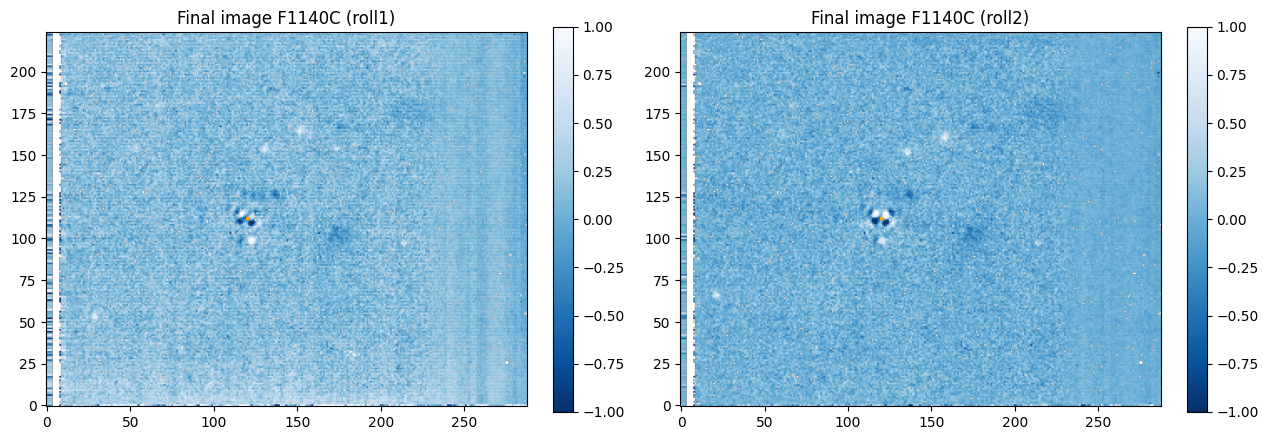

In [30]:
# Final image for both roll 1 and roll 2
image_r1, err_image_r1, P = reference_subtract(data_r1_clean, data_ref_clean, err_r1, err_ref, corono_center)
image_r2, err_image_r2, P = reference_subtract(data_r2_clean, data_ref_clean, err_r2, err_ref, corono_center)

# Plot
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_r1, origin='lower', cmap='Blues_r', vmin=-1, vmax=1.0)
plt.colorbar(fraction=0.04, pad=0.05)
plt.scatter(corono_center[0], corono_center[1], color='orange', marker='*', s=5, label='Coronograph center')
plt.title('Final image F1140C (roll1)')

plt.subplot(1, 2, 2)
plt.imshow(image_r2, origin='lower', cmap='Blues_r', vmin=-1.0, vmax=1.0)
plt.colorbar(fraction=0.04, pad=0.05)
plt.scatter(corono_center[0], corono_center[1], color='orange', marker='*', s=5, label='Coronograph center')
plt.title('Final image F1140C (roll2)')

#Save FITS  
hdu_sci_r1 = fits.PrimaryHDU(image_r1, header=hdr_r1)
hdu_err_r1 = fits.ImageHDU(err_image_r1, name='ERR')
hdul_out_r1 = fits.HDUList([hdu_sci_r1, hdu_err_r1])
hdul_out_r1.writeto(output_files_r1_fits, overwrite=True)

hdu_sci = fits.PrimaryHDU(image_r2, header=hdr_r2)
hdu_err = fits.ImageHDU(err_image_r2, name='ERR')
hdul_out = fits.HDUList([hdu_sci, hdu_err])
hdul_out.writeto(output_files_r2_fits, overwrite=True)

### Crop the image and rotation with Nup

121.44701280689611
129.26840425270544


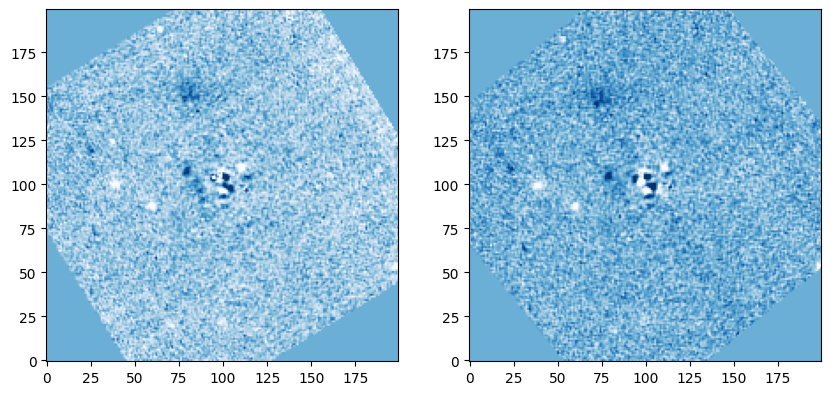

In [31]:
#Rotation angle (to align Y axis with the North)
pa_aper_roll1 = fits.open(output_files_r1_fits)[0].header['PA_APER']
pa_aper_roll2 = fits.open(output_files_r2_fits)[0].header['PA_APER']
print(pa_aper_roll1)
print(pa_aper_roll2)

crop_image_r1 = np.nan_to_num(crop_center(image_r1, corono_center), nan=0.0)
crop_err_r1 = np.nan_to_num(crop_center(err_image_r1,corono_center), nan=0.0)

newcx, newcy = crop_image_r1.shape[0]//2, crop_image_r1.shape[1]//2

rotate_image_r1 = rotate_images(crop_image_r1, (newcy, newcx), window_size=2, ang=-pa_aper_roll1)
rotate_err_r1 = rotate_images(crop_err_r1, (newcy, newcx), window_size=2, ang=-pa_aper_roll1)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(rotate_image_r1, origin='lower', cmap='Blues_r', vmin=-0.5, vmax=0.5)

output_rotate_fits_r1 = os.path.join(coron3_dir, 'image_roll1_Nup.fits')
hdu_sci_r1 = fits.PrimaryHDU(rotate_image_r1, header=hdr_r1)
hdu_err_r1 = fits.ImageHDU(rotate_err_r1, name='ERR')
hdul_out_r1 = fits.HDUList([hdu_sci_r1, hdu_err_r1])
hdul_out_r1.writeto(output_rotate_fits_r1, overwrite=True)

crop_image_r2 = np.nan_to_num(crop_center(image_r2, corono_center), nan=0.0)
crop_err_r2 = np.nan_to_num(crop_center(err_image_r2,corono_center), nan=0.0)

newcx, newcy = crop_image_r2.shape[0]//2, crop_image_r2.shape[1]//2

rotate_image_r2 = rotate_images(crop_image_r2, (newcy, newcx), window_size=2, ang=-pa_aper_roll2)
rotate_err_r2 = rotate_images(crop_err_r2, (newcy, newcx), window_size=2, ang=-pa_aper_roll2)

plt.subplot(1, 2, 2)
plt.imshow(rotate_image_r2, origin='lower', cmap='Blues_r', vmin=-0.5, vmax=0.5)

output_rotate_fits_r2 = os.path.join(coron3_dir, 'image_roll2_Nup.fits')
hdu_sci_r2 = fits.PrimaryHDU(rotate_image_r2, header=hdr_r2)
hdu_err_r2 = fits.ImageHDU(rotate_err_r2, name='ERR')
hdul_out_r2 = fits.HDUList([hdu_sci_r2, hdu_err_r2])
hdul_out_r2.writeto(output_rotate_fits_r2, overwrite=True)

## b. Linear combination with 9 dithers

In [36]:
rmin= 0.5
rmax= 5.0

###Sci Roll 1
sub_linear_r1, P_r1_lin = optimize_refs(data_r1_clean, data_ref_clean, (corono_center[1], corono_center[0]), rmin, rmax)
err_new_ref_r1 = np.sqrt(sum((P_r1_lin[i]**2) * (err_ref[i]**2) for i in range (len(err_ref))))
err_residual_lin_r1 = np.sqrt(err_r1**2 + err_new_ref_r1**2)

###Sci Roll 2
sub_linear_r2, P_r2_lin = optimize_refs(data_r2_clean, data_ref_clean, (corono_center[1], corono_center[0]), rmin, rmax)
err_new_ref_r2 = np.sqrt(sum((P_r2_lin[i]**2) * (err_ref[i]**2) for i in range (len(err_ref))))
err_residual_lin_r2 = np.sqrt(err_r2**2 + err_new_ref_r2**2)

# Plot
plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 1)
plt.imshow(sub_linear_r1, origin='lower', cmap='Blues_r', vmin=-0.6, vmax=0.6)
plt.colorbar()
plt.scatter(corono_center[0], corono_center[1], color='orange', marker='*', s=5, label='Coronograph center')
plt.title("Residuals Minimized (Roll1)")

plt.subplot(1, 2, 2)
plt.imshow(sub_linear_r2, origin='lower', cmap='Blues_r', vmin=-0.6, vmax=0.6)
plt.colorbar()
plt.scatter(corono_center[0], corono_center[1], color='orange', marker='*', s=5, label='Coronograph center')
plt.title("Residuals Minimized (Roll2)")

hdu_sci = fits.PrimaryHDU(sub_linear_r2, header=hdr_r2)
hdu_err = fits.ImageHDU(err_residual_lin_r2, name='ERR')
hdul_out = fits.HDUList([hdu_sci, hdu_err])
hdul_out.writeto(output_files_r2_lin_fits, overwrite=True)

KeyboardInterrupt: 

### Crop the center and rotate the images

121.44701280689611
129.26840425270544


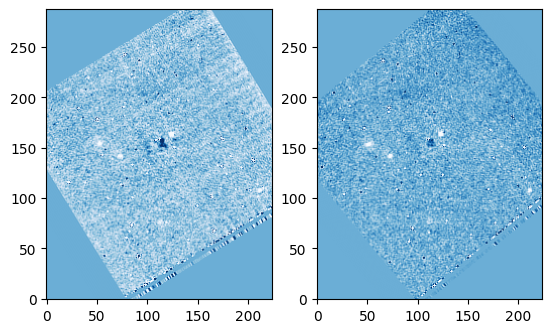

In [33]:
#Rotation angle (to align Y axis with the North)
pa_aper_roll1 = fits.open(output_files_r1_fits)[0].header['PA_APER']
pa_aper_roll2 = fits.open(output_files_r2_fits)[0].header['PA_APER']
print(pa_aper_roll1)
print(pa_aper_roll2)

rotate_image_lin_r1 = rotate_images(np.nan_to_num(sub_linear_r1, nan=0.0), corono_center,window_size=2, ang=-pa_aper_roll1)
rotate_err_lin_r1 = rotate_images(np.nan_to_num(err_residual_lin_r1, nan=0.0), corono_center,window_size=2, ang=-pa_aper_roll1)

plt.subplot(1, 2, 1)
plt.imshow(rotate_image_lin_r1, origin='lower', cmap='Blues_r', vmin=-0.5, vmax=0.5)


rotate_image_lin_r2 = rotate_images(np.nan_to_num(sub_linear_r2, nan=0.0), corono_center,window_size=2, ang=-pa_aper_roll2)
rotate_err_lin_r2 = rotate_images(np.nan_to_num(err_residual_lin_r2, nan=0.0), corono_center,window_size=2, ang=-pa_aper_roll2)

plt.subplot(1, 2, 2)
plt.imshow(rotate_image_lin_r2, origin='lower', cmap='Blues_r', vmin=-0.5, vmax=0.5)

output_rotate_fits_r1 = os.path.join(coron3_dir, 'image_lin_roll1_Nup.fits')
hdu_sci_r1 = fits.PrimaryHDU(rotate_image_lin_r1, header=hdr_r1)
hdu_err_r1 = fits.ImageHDU(rotate_err_lin_r1, name='ERR')
hdul_out_r1 = fits.HDUList([hdu_sci_r1, hdu_err_r1])
hdul_out_r1.writeto(output_rotate_fits_r1, overwrite=True)

output_rotate_fits_r2 = os.path.join(coron3_dir, 'image_lin_roll2_Nup.fits')
hdu_sci_r2 = fits.PrimaryHDU(rotate_image_lin_r2, header=hdr_r2)
hdu_err_r2 = fits.ImageHDU(rotate_err_lin_r2, name='ERR')
hdul_out_r2 = fits.HDUList([hdu_sci_r2, hdu_err_r2])
hdul_out_r2.writeto(output_rotate_fits_r2, overwrite=True)

## c. Linear combination with reference star from a library 

In [34]:
ref_root_dir = '/Users/mcourtoux/these/raw_data/ref_library/F1140C/REF'

data_ref_clean, ref_names = load_reference_library(ref_root_dir)
nb_refs = len(data_ref_clean)

Loaded 126 reference images


In [ ]:
rmin = 0.5
rmax = 5.0
h, w = np.shape(data_r1_clean)
mask = create_annular_mask(h, w, corono_center, rmin, rmax)
mask_total = ~mask & ~np.isnan(data_r1_clean)

# -------- Normalisation of the reference in the mask ----------
for i in range(nb_refs):
    norm = np.nanmedian(data_ref_clean[i][mask_total])
    if norm > 0:
        data_ref_clean[i] /= norm

for i in range(3):
    print(np.nanmedian(data_ref_clean[i][mask_total]))

# --------------------------------------------------------------
data_mask = np.zeros_like(data_r1_clean)
data_ref_mask = [np.zeros_like(data_ref_clean[i]) for i in range(nb_refs)]
data_mask[mask_total] = data_r1_clean[mask_total]
for i in range (nb_refs):
    data_ref_mask[i][mask_total] = data_ref_clean[i][mask_total]

plt.figure()
plt.imshow(data_mask, origin='lower', cmap='Blues_r')

data_sub_r1, P_r1_ref_lib = optimize_refs(data_r1_clean, data_ref_mask, (corono_center[1], corono_center[0]), rmin=rmin, rmax=rmax)
best_ref = sum(P[i]*data_ref_clean[i] for i in range(nb_refs))
data_r1_sub_clean = np.nan_to_num(data_sub_r1-best_ref, nan=0.0)

#Rotation of the image of the PA_APER angle
data_sub_rot = rotate_images(data_r1_sub_clean, center_corono, 200, -pa_aper)

plt.figure()
plt.imshow(data_sub_rot, origin='lower', cmap='Blues_r')

#hdu = fits.PrimaryHDU(data_sub_rot)
#hdr = hdu.header
#hdu.writeto(new_dir+f'/{targ}_opt_lin_{rmax}_norm.fits', overwrite=True)


1.0
1.0
1.0
